<center> <span style="color:indigo">Detección de Anomalías en Contrataciones Públicas mediante Aprendizaje Automático y Análisis Estadístico  </span> </center>

<div style="text-align: center;">
<img src="https://upload.wikimedia.org/wikipedia/commons/2/2b/Centro_Universitario_del_Guadalajara_Logo.png" alt="Drawing" style="width: 800px;"/>
</div>

<center> <span style="color:indigo">PROYECTO INTEGRADOR 3ER SEMESTRE</span> </center>


**Integrantes:**

*José Evaristo Escalante Chávez.*

*Leonardo Daniel Mora Hernandez.*

*Ernesto Alejandro Ramirez Castro.*

*Kevin Alejandro Cisneros García.*



In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import pandas as pd
import seaborn as sns
import scipy.stats as stats
from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import time

# Importación del dataset

In [ ]:
url = 'https://raw.githubusercontent.com/leonardomora6239/Proyecto_integrador_3er_Semestre_CUGDL/main/PPEF_2026.csv'
df = pd.read_csv(url, encoding='latin1')
df.index = df["CICLO"]
df.head()

/tmp/ipykernel_3530/3816104490.py:2: DtypeWarning: Columns (31) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(url, encoding='latin1')


,CICLO,ID_RAMO,DESC_RAMO,ID_UR,DESC_UR,GPO_FUNCIONAL,DESC_GPO_FUNCIONAL,ID_FUNCION,DESC_FUNCION,ID_SUBFUNCION,...,ID_PARTIDA_ESPECIFICA,DESC_PARTIDA_ESPECIFICA,ID_TIPOGASTO,DESC_TIPOGASTO,ID_FF,DESC_FF,ID_ENTIDAD_FEDERATIVA,ENTIDAD_FEDERATIVA,ID_CLAVE_CARTERA,MONTO_PROYECTO
CICLO,,,,,,,,,,,,,,,,,,,,,
2026,2026,1,Poder Legislativo,100,H. Cámara de Diputados,1,Gobierno,1,Legislación,1,...,62201,Obras de construcción para edificios no habita...,3,Gasto de obra pública,1,Recursos fiscales,9,Ciudad de México,0,"303,809,521.00"
2026,2026,1,Poder Legislativo,100,H. Cámara de Diputados,1,Gobierno,1,Legislación,1,...,11101,Dietas (Ramos Autónomos),1,Gasto corriente,1,Recursos fiscales,9,Ciudad de México,0,"631,877,879.00"
2026,2026,1,Poder Legislativo,100,H. Cámara de Diputados,1,Gobierno,1,Legislación,1,...,11301,Sueldos base,1,Gasto corriente,1,Recursos fiscales,9,Ciudad de México,0,"598,141,798.00"
2026,2026,1,Poder Legislativo,100,H. Cámara de Diputados,1,Gobierno,1,Legislación,1,...,12101,Honorarios,1,Gasto corriente,1,Recursos fiscales,9,Ciudad de México,0,"1,006,550,553.00"
2026,2026,1,Poder Legislativo,100,H. Cámara de Diputados,1,Gobierno,1,Legislación,1,...,12301,Retribuciones por servicios de carácter social,1,Gasto corriente,1,Recursos fiscales,9,Ciudad de México,0,"1,333,333.00"


# Limpieza de la base de datos.

In [ ]:
y_objetivo = df["MONTO_PROYECTO"]

df = df.dropna().drop_duplicates()

df.info()
df.describe()


<class 'pandas.core.frame.DataFrame'>
Index: 129908 entries, 2026 to 2026
Data columns (total 33 columns):
 #   Column                   Non-Null Count   Dtype 
---  ------                   --------------   ----- 
 0   CICLO                    129908 non-null  int64 
 1   ID_RAMO                  129908 non-null  int64 
 2   DESC_RAMO                129908 non-null  object
 3   ID_UR                    129908 non-null  object
 4   DESC_UR                  129908 non-null  object
 5   GPO_FUNCIONAL            129908 non-null  int64 
 6   DESC_GPO_FUNCIONAL       129908 non-null  object
 7   ID_FUNCION               129908 non-null  int64 
 8   DESC_FUNCION             129908 non-null  object
 9   ID_SUBFUNCION            129908 non-null  int64 
 10  DESC_SUBFUNCION          129908 non-null  object
 11  ID_AI                    129908 non-null  int64 
 12  DESC_AI                  129908 non-null  object
 13  ID_MODALIDAD             129908 non-null  object
 14  DESC_MODALIDAD          

,CICLO,ID_RAMO,GPO_FUNCIONAL,ID_FUNCION,ID_SUBFUNCION,ID_AI,ID_PP,ID_CAPITULO,ID_CONCEPTO,ID_PARTIDA_GENERICA,ID_PARTIDA_ESPECIFICA,ID_TIPOGASTO,ID_FF,ID_ENTIDAD_FEDERATIVA
count,129908.0,129908.000000,129908.000000,129908.000000,129908.000000,129908.000000,129908.000000,129908.000000,129908.000000,129908.000000,129908.000000,129908.000000,129908.000000,129908.000000
mean,2026.0,28.390222,1.887890,3.697902,3.325985,10.877044,21.565493,2084.759984,2499.214829,253.523139,25354.658058,1.133140,1.619207,14.147651
std,0.0,17.352004,0.801619,1.930205,2.194260,33.829358,28.778620,1296.314266,1310.242774,131.395207,13139.887209,0.408946,1.214167,8.375140
min,2026.0,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1000.000000,1100.000000,111.000000,11101.000000,0.000000,1.000000,1.000000
25%,2026.0,13.000000,1.000000,3.000000,2.000000,2.000000,2.000000,1000.000000,1400.000000,144.000000,14401.000000,1.000000,1.000000,9.000000
50%,2026.0,22.000000,2.000000,3.000000,2.000000,4.000000,10.000000,2000.000000,2200.000000,221.000000,22106.000000,1.000000,1.000000,9.000000
75%,2026.0,50.000000,3.000000,5.000000,5.000000,8.000000,31.000000,3000.000000,3300.000000,336.000000,33605.000000,1.000000,1.000000,21.000000
max,2026.0,56.000000,4.000000,9.000000,9.000000,235.000000,320.000000,9000.000000,9900.000000,991.000000,99101.000000,9.000000,4.000000,34.000000


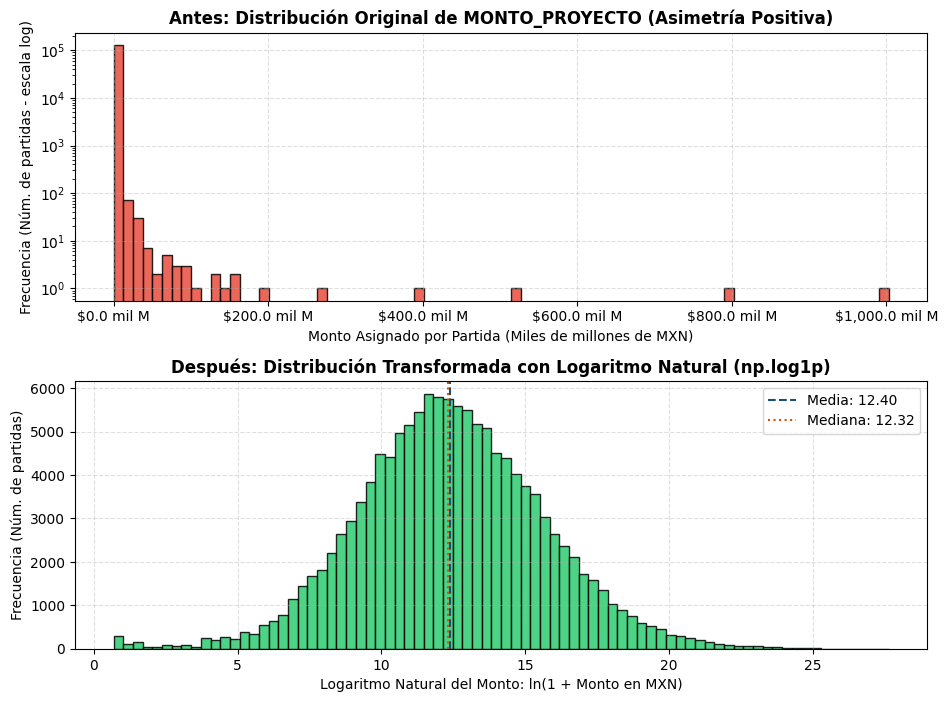

In [ ]:
df['MONTO_PROYECTO'] = pd.to_numeric(df['MONTO_PROYECTO'].astype(str).str.replace(',', ''), errors='coerce')
df = df.dropna(subset=['MONTO_PROYECTO'])

df = df[df['MONTO_PROYECTO'] > 0]


#------------- Creación de la variable objetivo categórica (RIESGO_CORRUPCION)------------


#    Aplicamos una transformación logarítmica para mitigar de asimetría de los datos
df['MONTO_LOG'] = np.log1p(df['MONTO_PROYECTO'])

fig, axes = plt.subplots(2, 1, figsize=(11, 8))

# --- Gráfica superior (Datos originales) ---
axes[0].hist(df['MONTO_PROYECTO'], bins=80, color='#e74c3c', edgecolor='black', alpha=0.85)
axes[0].set_yscale('log')
axes[0].xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f'${x/1e9:,.1f} mil M'))
axes[0].set_title('Antes: Distribución Original de MONTO_PROYECTO (Asimetría Positiva)', fontweight='bold')
axes[0].set_xlabel('Monto Asignado por Partida (Miles de millones de MXN)')
axes[0].set_ylabel('Frecuencia (Núm. de partidas - escala log)')
axes[0].grid(axis='both', linestyle='--', alpha=0.4)

# --- Gráfica inferior (Datos transformados) ---
media_log = df['MONTO_LOG'].mean()
mediana_log = df['MONTO_LOG'].median()

axes[1].hist(df['MONTO_LOG'], bins=80, color='#2ecc71', edgecolor='black', alpha=0.85)
axes[1].axvline(media_log, color='#1b4f72', linestyle='--', linewidth=1.5, label=f'Media: {media_log:.2f}')
axes[1].axvline(mediana_log, color='#d35400', linestyle=':', linewidth=1.5, label=f'Mediana: {mediana_log:.2f}')
axes[1].set_title('Después: Distribución Transformada con Logaritmo Natural (np.log1p)', fontweight='bold')
axes[1].set_xlabel('Logaritmo Natural del Monto: ln(1 + Monto en MXN)')
axes[1].set_ylabel('Frecuencia (Núm. de partidas)')
axes[1].legend()
axes[1].grid(axis='both', linestyle='--', alpha=0.4)

fig.subplots_adjust(hspace=0.3)
plt.show()

In [ ]:
#2.2.- Calcular el promedio logarítmico del monto agrupado por partida (ID_CONCEPTO)
promedios_partida = df.groupby('ID_CONCEPTO')['MONTO_LOG'].transform('mean')
df['DESVIACION'] = df['MONTO_LOG'] - promedios_partida


#3------------------Función de umbrales para catalogar el riesgo de corrupción---------
def asignar_riesgo(desviacion):
    if desviacion < -0.5 or desviacion > 2.0:
      return 'Alto'  #Desvío crítico de fondos
    else:
      return 'Bajo' #Comportamiento alineado a la inversión normal de la partida

#4-------------Generar la variable objetivo categórica en el DataFrame--------------------
df['RIESGO_CORRUPCION'] = df['DESVIACION'].apply(asignar_riesgo)
print("Distribución del riesgo de corrupción:")
print(df['RIESGO_CORRUPCION'].value_counts())

Distribución del riesgo de corrupción:
RIESGO_CORRUPCION
Alto    83819
Bajo    46088
Name: count, dtype: int64


# Ejecución y comparación de los modelos de ML: (Logistic Regression, Desicion Tree y Random Forest)

In [ ]:
#1----------Codificar la variable objetivo (Alto=0, Bajo=1)-------
le_y = LabelEncoder()
y_encoded = le_y.fit_transform(df['RIESGO_CORRUPCION'])

df['ID_UR'] = df['ID_UR'].astype(str).str.strip()

#3----------calculamos la tasa de riesgo 'Alto' por cada Unidad Responsable(UR)---------
es_alto = (df['RIESGO_CORRUPCION'] == 'Alto').astype(int)
ur_riesgo_map = es_alto.groupby(df['ID_UR']).mean()
df['ID_UR_ENCODED'] = df['ID_UR'].map(ur_riesgo_map)


variables_features = [
    'ID_RAMO', 'ID_UR_ENCODED', 'GPO_FUNCIONAL', 'ID_FUNCION',
    'ID_SUBFUNCION', 'ID_AI', 'ID_PP', 'ID_CAPITULO', 'ID_CONCEPTO'
]

X = df[variables_features].copy()
for col in X.columns:
    X[col] = pd.to_numeric(X[col], errors='coerce')

#4.2.- Rellenar posibles valores nulos que hayan surgido en la conversión con 0
X = X.fillna(0)
y = y_encoded

#5--------Fase de la división en Entrenamiento y Prueba------------
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

#6--------Estandarización------------
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

#7----------Entrenamiento y comparación de modelos---------------
modelos = {
    'Regresión Logística': LogisticRegression(max_iter=1000, random_state=42),
    'Árbol de Decisión': DecisionTreeClassifier(max_depth=10, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1)
}

resultados = []
for nombre, modelo in modelos.items():
    inicio = time.time()
    modelo.fit(X_train_scaled, y_train)
    tiempo_ejecucion = time.time() - inicio
    y_pred = modelo.predict(X_test_scaled)

    resultados.append({
        'Modelo': nombre,
        'Accuracy (Exactitud)': round(accuracy_score(y_test, y_pred), 4),
        'Precision': round(precision_score(y_test, y_pred, average='macro', zero_division=0), 4),
        'Recall (Sensibilidad)': round(recall_score(y_test, y_pred, average='macro', zero_division=0), 4),
        'F1-Score': round(f1_score(y_test, y_pred, average='macro', zero_division=0), 4),
        'Tiempo (seg)': round(tiempo_ejecucion, 3)
    })

df_comparativa = pd.DataFrame(resultados)
print("\n=== TABLA COMPARATIVA DE MODELOS FINAL ===")
df_comparativa


=== TABLA COMPARATIVA DE MODELOS FINAL ===


,Modelo,Accuracy (Exactitud),Precision,Recall (Sensibilidad),F1-Score,Tiempo (seg)
0,Regresión Logística,0.6469,0.5871,0.5135,0.4393,0.441
1,Árbol de Decisión,0.6748,0.6447,0.5780,0.5658,0.765
2,Random Forest,0.6771,0.6637,0.5693,0.5466,13.345


# Pruebas de hipótesis

In [ ]:
# -------------------------------------------------------------------------
# PRUEBA EXTRA: Bondad de Ajuste (Kolmogorov-Smirnov) para MONTO_LOG
# -------------------------------------------------------------------------
monto_log_std = (df['MONTO_LOG'] - df['MONTO_LOG'].mean()) / df['MONTO_LOG'].std()

stat_ks, p_val_ks = stats.kstest(monto_log_std, 'norm')

print("=== 1. PRUEBA DE BONDAD DE AJUSTE (KS) ===")
print(f"Estadístico D: {stat_ks:.4f}")
print(f"p-valor: {p_val_ks}")
if p_val_ks < 0.05:
    print("Conclusión: Se rechaza H0. Los datos NO siguen una distribución normal pura.")
else:
    print("Conclusión: No se rechaza H0. Los datos se ajustan a una distribución normal.")


=== 1. PRUEBA DE BONDAD DE AJUSTE (KS) ===
Estadístico D: 0.0149
p-valor: 1.9354743976194857e-25
Conclusión: Se rechaza H0. Los datos NO siguen una distribución normal pura.


In [ ]:
# -------------------------------------------------------------------------
# 2.- Observaciones Pareadas (t-test pareado)
# -------------------------------------------------------------------------
# Tomamos dos partidas consecutivas o grupos pareados para la prueba
muestra_a = df[df['ID_CONCEPTO'] == 1100]['MONTO_LOG'].dropna()
muestra_b = df[df['ID_CONCEPTO'] == 1200]['MONTO_LOG'].dropna()

n_min = min(len(muestra_a), len(muestra_b))
stat_ttest, p_val_ttest = stats.ttest_rel(muestra_a.iloc[:n_min], muestra_b.iloc[:n_min])

print("\n=== 2. PRUEBA DE OBSERVACIONES PAREADAS ===")
print(f"Estadístico t: {stat_ttest:.4f}")
print(f"p-valor: {p_val_ttest}")
if p_val_ttest < 0.05:
    print("Conclusión: Se rechaza H0. Existe diferencia significativa entre las medias pareadas.")
else:
    print("Conclusión: No se rechaza H0. No hay diferencia significativa.")



=== 2. PRUEBA DE OBSERVACIONES PAREADAS ===
Estadístico t: 15.2422
p-valor: 8.497039197539876e-49
Conclusión: Se rechaza H0. Existe diferencia significativa entre las medias pareadas.


### Prueba ANOVA

In [ ]:
def SSA(n, k, yi_mean, y_mean):
    summ = 0.0
    for i in range(k):
        summ += (yi_mean[i] - y_mean)**2
    return n * summ

def SSE(n, k, yij, yi_mean):
    summ = 0.0
    for i in range(k):
        for j in range(n):
            # yij[j, i] -> Elemento en la fila 'j' (partida) de la columna 'i' (ramo)
            summ += (yij[j, i] - yi_mean[i])**2
    return summ

n = 500
k = 3

g0 = df[df['ID_RAMO'] == 11]['MONTO_LOG'].dropna().values[:n]
g1 = df[df['ID_RAMO'] == 12]['MONTO_LOG'].dropna().values[:n]
g2 = df[df['ID_RAMO'] == 7]['MONTO_LOG'].dropna().values[:n]

yij = np.zeros((n, k), dtype=np.float64)

yij[:, 0] = g0  # Columna 0: Educación
yij[:, 1] = g1  # Columna 1: Salud
yij[:, 2] = g2  # Columna 2: Defensa

# =====================================================================
# PASO 3: CÁLCULO DE PROMEDIOS
# =====================================================================
yi_mean = np.mean(yij, axis=0)

y_mean = np.mean(yij)

# =====================================================================
# PASO 4: EVALUACIÓN DE SUMAS DE CUADRADOS Y VARIANZAS
# =====================================================================
SSA_val = SSA(n, k, yi_mean, y_mean) # Suma de Cuadrados de Tratamientos
SSE_val = SSE(n, k, yij, yi_mean)    # Suma de Cuadrados del Error

# Grados de libertad
df_tratamientos = k - 1
df_error = k * (n - 1)

# Cuadrados Medios (Varianza entre grupos vs Varianza dentro de grupos)
s1 = SSA_val / df_tratamientos  # MSA
s2 = SSE_val / df_error         # MSE

# =====================================================================
# PASO 5: PRUEBA DE HIPÓTESIS
# =====================================================================
F_stat = s1 / s2

p_val = 1.0 - stats.f.cdf(F_stat, df_tratamientos, df_error)

print(f"Estadístico F calculado: {F_stat:.4f}")
print(f"p-valor: {p_val}")

Estadístico F calculado: 140.8801
p-valor: 1.1102230246251565e-16


In [ ]:
df["RIESGO_CORRUPCION"].value_counts()

,count
RIESGO_CORRUPCION,
Alto,83819
Bajo,46088


In [ ]:
df["ENTIDAD_FEDERATIVA"].value_counts()

,count
ENTIDAD_FEDERATIVA,
Ciudad de México,44161
Veracruz,3968
Estado de México,3593
Jalisco,3500
Baja California,3305
Chiapas,3004
Guerrero,2990
Oaxaca,2972
Yucatán,2940


In [ ]:
df

,CICLO,ID_RAMO,DESC_RAMO,ID_UR,DESC_UR,GPO_FUNCIONAL,DESC_GPO_FUNCIONAL,ID_FUNCION,DESC_FUNCION,ID_SUBFUNCION,...,ID_FF,DESC_FF,ID_ENTIDAD_FEDERATIVA,ENTIDAD_FEDERATIVA,ID_CLAVE_CARTERA,MONTO_PROYECTO,MONTO_LOG,DESVIACION,RIESGO_CORRUPCION,ID_UR_ENCODED
CICLO,,,,,,,,,,,,,,,,,,,,,
2026,2026,1,Poder Legislativo,100,H. Cámara de Diputados,1,Gobierno,1,Legislación,1,...,1,Recursos fiscales,9,Ciudad de México,0,3.038095e+08,19.531911,2.881829,Alto,0.655741
2026,2026,1,Poder Legislativo,100,H. Cámara de Diputados,1,Gobierno,1,Legislación,1,...,1,Recursos fiscales,9,Ciudad de México,0,6.318779e+08,20.264207,4.500734,Alto,0.655741
2026,2026,1,Poder Legislativo,100,H. Cámara de Diputados,1,Gobierno,1,Legislación,1,...,1,Recursos fiscales,9,Ciudad de México,0,5.981418e+08,20.209338,4.445865,Alto,0.655741
2026,2026,1,Poder Legislativo,100,H. Cámara de Diputados,1,Gobierno,1,Legislación,1,...,1,Recursos fiscales,9,Ciudad de México,0,1.006551e+09,20.729795,6.098366,Alto,0.655741
2026,2026,1,Poder Legislativo,100,H. Cámara de Diputados,1,Gobierno,1,Legislación,1,...,1,Recursos fiscales,9,Ciudad de México,0,1.333333e+06,14.103193,-0.528236,Alto,0.655741
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026,2026,53,Comisión Federal de Electricidad,TVV,Comisión Federal de Electricidad,3,Desarrollo Económico,3,Combustibles y Energía,5,...,4,Ingresos Propios,9,Ciudad de México,0,3.404100e+04,10.435350,-1.915678,Alto,0.680141
2026,2026,53,Comisión Federal de Electricidad,TVV,Comisión Federal de Electricidad,3,Desarrollo Económico,3,Combustibles y Energía,5,...,4,Ingresos Propios,9,Ciudad de México,0,4.000000e+06,15.201805,2.850777,Alto,0.680141
2026,2026,53,Comisión Federal de Electricidad,TVV,Comisión Federal de Electricidad,3,Desarrollo Económico,3,Combustibles y Energía,5,...,4,Ingresos Propios,9,Ciudad de México,0,9.877400e+04,11.500600,-2.052773,Alto,0.680141


### Figuras

/tmp/ipykernel_3530/1736531573.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_ramos.values, y=top_ramos.index, palette='Reds_r')


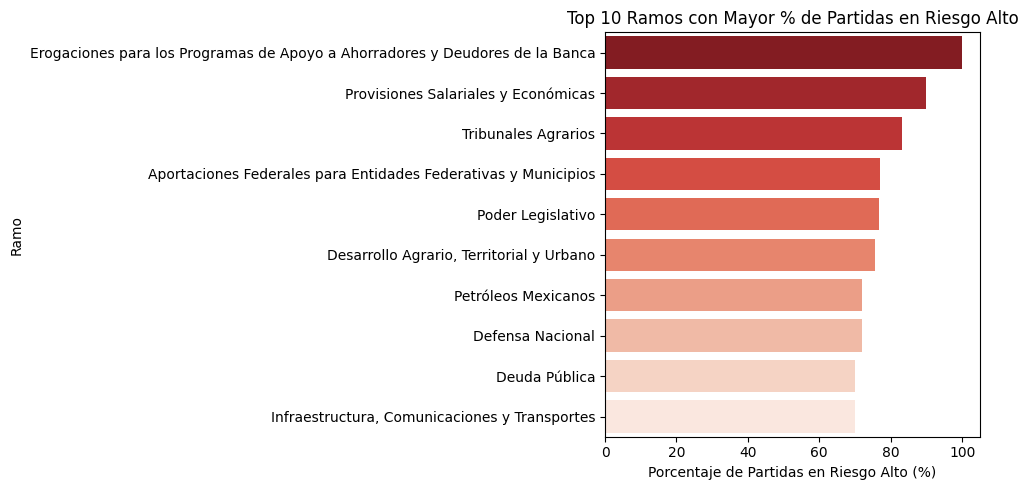

In [ ]:
top_ramos = df.groupby('DESC_RAMO')['RIESGO_CORRUPCION'].apply(lambda x: (x == 'Alto').mean() * 100).nlargest(10)

plt.figure(figsize=(10, 5))
sns.barplot(x=top_ramos.values, y=top_ramos.index, palette='Reds_r')
plt.title('Top 10 Ramos con Mayor % de Partidas en Riesgo Alto')
plt.xlabel('Porcentaje de Partidas en Riesgo Alto (%)')
plt.ylabel('Ramo')
plt.tight_layout()
plt.show()

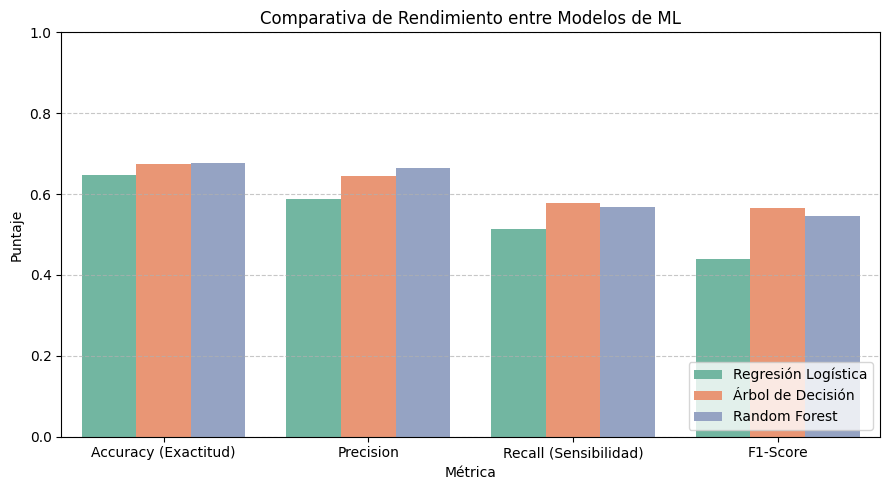

In [ ]:
df_melted = df_comparativa.melt(id_vars=['Modelo', 'Tiempo (seg)'],
                                var_name='Métrica',
                                value_name='Valor')

plt.figure(figsize=(9, 5))
sns.barplot(data=df_melted, x='Métrica', y='Valor', hue='Modelo', palette='Set2')
plt.title('Comparativa de Rendimiento entre Modelos de ML')
plt.ylim(0, 1)
plt.ylabel('Puntaje')
plt.legend(loc='lower right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

/tmp/ipykernel_3530/2161143611.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importancia', y='Variable', data=feature_imp_df, palette='viridis')


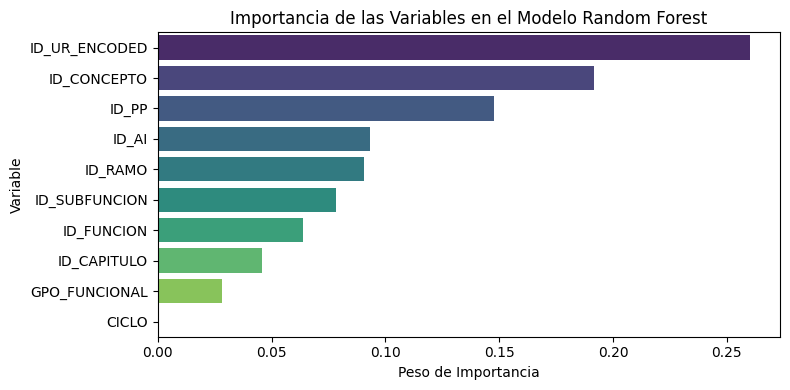

In [ ]:

rf_model = modelos['Random Forest']

importances = rf_model.feature_importances_
feature_imp_df = pd.DataFrame({'Variable': variables_features, 'Importancia': importances})
feature_imp_df = feature_imp_df.sort_values(by='Importancia', ascending=False)

plt.figure(figsize=(8, 4))
sns.barplot(x='Importancia', y='Variable', data=feature_imp_df, palette='viridis')
plt.title('Importancia de las Variables en el Modelo Random Forest')
plt.xlabel('Peso de Importancia')
plt.ylabel('Variable')
plt.tight_layout()
plt.show()